In [28]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [12]:
#dataset
layers = tf.keras.layers
df = pd.read_csv("ecg.csv",header=None)
keras.utils.set_random_seed(42)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [14]:
#split n scale
X = df.iloc[:,:-1].values.astype("float32")
y = (df.iloc[:,-1].values == 0).astype(int)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
scaler = MinMaxScaler().fit(Xtr[ytr == 0])
Xtrn = scaler.transform(Xtr[ytr == 0])
Xtes = scaler.transform(Xte)
print(Xtrn.shape, yte.sum(),len(yte))

(2335, 140) 416 1000


In [20]:
#layers
inp = keras.Input(shape=(140,))
x = layers.Dense(64,activation="relu")(inp)
x = layers.Dense(32,activation="relu")(x)
z = layers.Dense(16,activation="relu")(x)
x = layers.Dense(32,activation="relu")(z)
x = layers.Dense(64,activation="relu")(x)
out = layers.Dense(140,activation="sigmoid")(x)
ae = keras.Model(inp,out)
ae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,388 (91.36 KB)

 Trainable params: 23,388 (91.36 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
#compile
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
hist = ae.fit(Xtrn,Xtrn,batch_size=64,validation_split=0.1,epochs=40)

Epoch 1/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0216 - mae: 0.1166 - val_loss: 0.0117 - val_mae: 0.0766
Epoch 2/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0105 - mae: 0.0722 - val_loss: 0.0078 - val_mae: 0.0603
Epoch 3/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0073 - mae: 0.0597 - val_loss: 0.0064 - val_mae: 0.0547
Epoch 4/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0062 - mae: 0.0550 - val_loss: 0.0058 - val_mae: 0.0522
Epoch 5/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0057 - mae: 0.0526 - val_loss: 0.0053 - val_mae: 0.0496
Epoch 6/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0051 - mae: 0.0493 - val_loss: 0.0046 - val_mae: 0.0454
Epoch 7/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0044 - mae: 0.0454 - val_loss: 0.0042 - val_mae: 0.0427
Epoch 8/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0041 - mae: 0.0431 - val_loss: 0.0039 - val_mae: 0.0414
Epoch 9/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0038 - mae: 

In [30]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=1)
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=1)
threshold = np.percentile(err_train,95)
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 871us/step
0.00429486739449203 440 1000


In [31]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      0.995     0.954     0.974       584
     anomaly      0.939     0.993     0.965       416

    accuracy                          0.970      1000
   macro avg      0.967     0.973     0.969      1000
weighted avg      0.971     0.970     0.970      1000

[[557  27]
 [  3 413]]
0.9873


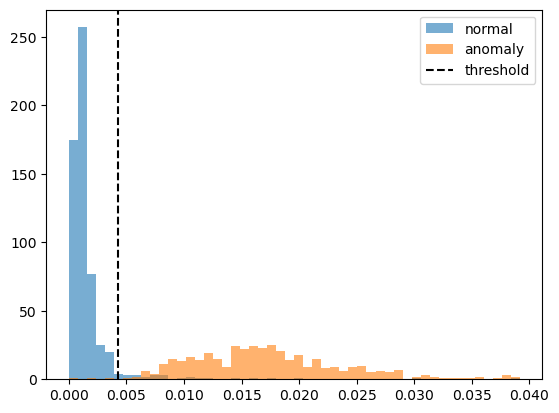

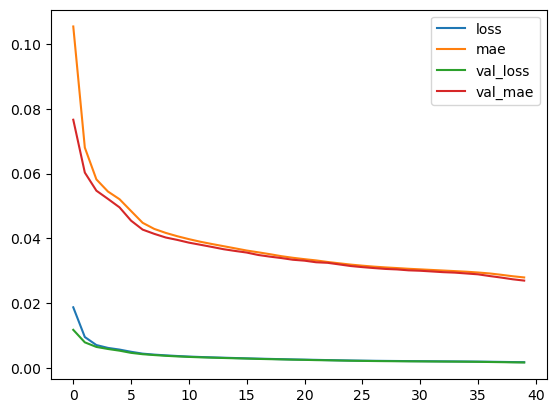

In [32]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

normal: error 0.001 -> ok
fraud : error 0.013 -> ANOMALY | threshold 0.004
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


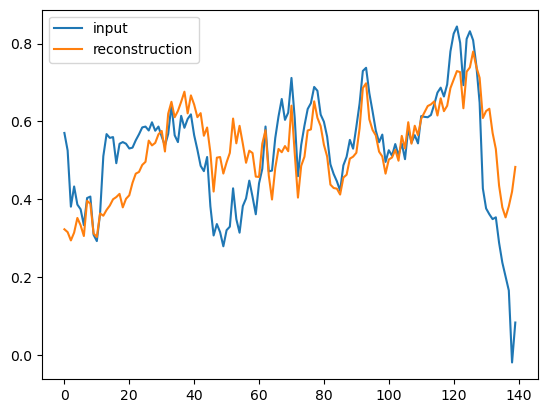

In [34]:
#one example
i = np.where(yte == 0)[0][0]                       # first normal transaction
j = np.where((yte == 1) & (pred == 1))[0][0]       # first fraud the model caught
print(f"normal: error {err_test[i]:.3f} -> {'ANOMALY' if pred[i] else 'ok'}")
print(f"fraud : error {err_test[j]:.3f} -> {'ANOMALY' if pred[j] else 'ok'} | threshold {threshold:.3f}")
plt.plot(Xtes[j], label="input"); plt.plot(ae.predict(Xtes[j:j+1])[0], label="reconstruction")
plt.legend(); plt.show()                           # the gap between the two lines is the error